# StockSense: Retail Store Inventory Management & Time-Series Demand Forecasting

## 📌 Project Overview & Methodological Rigor
In the retail sector, accurate demand forecasting is essential for supply chain resilience, working capital optimization, and stockout prevention. Traditional retail modeling pipelines often suffer from critical methodological vulnerabilities—most notably **data leakage** (conditioning predictions on same-day realized sales or revenue) and **lookahead bias** (using random cross-sectional train/test splits).

This project presents an audited, leakage-free, and production-grade time-series forecasting framework that predicts daily customer demand across **5 retail stores** and **20 product categories/SKUs** (100 distinct panel series over 760 consecutive days).

### Key Technical Highlights:
- **Data Leakage Audit & Rectification**: Same-day transactional information (`Units_Sold`, `Revenue`, `Units_Ordered`) removed from same-day predictors; past sales information transformed into strictly lagged features.
- **Time-Aware Feature Engineering**: Calendar indicators, pricing ratios, entity-grouped multi-horizon demand/sales lags, and strictly shifted rolling window statistics.
- **Time-Aware Validation**: Chronological 80/20 train/test split and date-grouped `TimeSeriesSplit` cross-validation.
- **Multi-Model Benchmark**: Rigorous comparison of Linear Regression, Decision Trees, Random Forest, Extra Trees, and XGBoost Regressors across MAE, RMSE, $R^2$, and MAPE.
- **Model Explainability**: Global feature importances and TreeSHAP value attribution.

In [1]:
# Core Libraries
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning & Preprocessing
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import shap

# Visual Styling
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11
np.random.seed(42)

print('All modules loaded successfully.')

All modules loaded successfully.


---
## 1. Data Ingestion & Schema Inspection
We load the raw dataset (`sales_data.csv`), parse the dates, sort chronologically, and inspect the panel time-series structure.

In [2]:
# Load dataset
data_path = 'sales_data.csv' if os.path.exists('sales_data.csv') else os.path.join('..', 'sales_data.csv')
df = pd.read_csv(data_path)

# Parse dates and sort chronologically by entity and date
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values(by=['Store_ID', 'Product_ID', 'Date']).reset_index(drop=True)

print(f'Dataset Dimensions: {df.shape[0]:,} rows, {df.shape[1]} columns')
print(f'Timeline: {df["Date"].min().strftime("%Y-%m-%d")} to {df["Date"].max().strftime("%Y-%m-%d")} ({df["Date"].nunique()} unique days)')
print(f'Stores: {df["Store_ID"].nunique()} | Products: {df["Product_ID"].nunique()} | Series Count: {df.groupby(["Store_ID", "Product_ID"]).ngroups}')
display(df.head())

Dataset Dimensions: 76,000 rows, 17 columns
Timeline: 2022-01-01 to 2024-01-30 (760 unique days)
Stores: 5 | Products: 20 | Series Count: 100


,Date,Store_ID,Product_ID,Category,Region,Inventory_Level,Units_Sold,Units_Ordered,Price,Revenue,Discount,Weather,Promotion,Competitor_Pricing,Seasonality,Epidemic,Demand
0,2022-01-01,S001,P0001,Electronics,North,195,102,252,72.72,7417.44,5,Snowy,No,85.73,Winter,No,115
1,2022-01-02,S001,P0001,Electronics,North,93,71,0,65.63,4659.73,5,Snowy,No,73.66,Winter,No,84
2,2022-01-03,S001,P0001,Electronics,North,274,142,229,68.55,9734.10,15,Snowy,Yes,80.73,Winter,No,132
3,2022-01-04,S001,P0001,Electronics,North,132,42,0,61.66,2589.72,10,Snowy,No,54.88,Winter,No,67
4,2022-01-05,S001,P0001,Electronics,North,319,129,0,59.56,7683.24,25,Snowy,Yes,57.34,Winter,No,110


In [3]:
# Data Quality & Missing Value Audit
null_summary = df.isnull().sum()
print('Missing Values per Column:')
print(null_summary)
print('\nSummary Statistics:')
display(df.describe().T)

Missing Values per Column:
Date                  0
Store_ID              0
Product_ID            0
Category              0
Region                0
Inventory_Level       0
Units_Sold            0
Units_Ordered         0
Price                 0
Revenue               0
Discount              0
Weather               0
Promotion             0
Competitor_Pricing    0
Seasonality           0
Epidemic              0
Demand                0
dtype: int64

Summary Statistics:


,count,mean,min,25%,50%,75%,max,std
Date,76000,2023-01-15 12:00:00,2022-01-01 00:00:00,2022-07-09 18:00:00,2023-01-15 12:00:00,2023-07-24 06:00:00,2024-01-30 00:00:00,NaN
Inventory_Level,76000.0,301.062842,0.0,136.0,227.0,408.0,2267.0,226.510161
Units_Sold,76000.0,88.827316,0.0,58.0,84.0,114.0,426.0,43.994525
Units_Ordered,76000.0,89.090645,0.0,0.0,0.0,121.0,1616.0,162.404627
Price,76000.0,67.726028,4.74,31.9975,64.5,95.83,228.03,39.377899
Revenue,76000.0,5990.790717,0.0,2426.595,4789.285,8349.3275,69859.74,4756.214481
Discount,76000.0,9.087039,0.0,5.0,10.0,10.0,25.0,7.475781
Competitor_Pricing,76000.0,69.454029,4.29,32.62,65.7,97.9325,261.22,40.943818
Demand,76000.0,104.317158,4.0,71.0,100.0,133.0,430.0,46.964801


---
## 2. Deep-Dive Methodological & Data Leakage Audit

### ⚠️ Why Naive Modeling Fails in Demand Forecasting
In initial iterations of this project, models achieved an artificially high $R^2 > 85\%$. Our audit reveals that this was caused by **direct target contamination**:

1. **Same-Day `Units_Sold`**: Realized sales on day $t$ is a direct downstream result of day $t$'s customer demand ($r = 0.833$). In a live production setting, today's sales cannot be known before making today's inventory and demand forecast.
2. **Same-Day `Revenue`**: $\text{Revenue}_t = \text{Units\_Sold}_t \times \text{Price}_t$. Knowing revenue is mathematically equivalent to knowing units sold.
3. **Same-Day `Units_Ordered`**: Restocking orders placed during day $t$ are reactive to same-day sales and inventory depletion.
4. **Random `train_test_split`**: Random cross-sectional row shuffling causes future records to contaminate the training set (lookahead bias).

Below, we empirically demonstrate the exact identity of revenue and the tight correlation between units sold and demand.

Max Absolute Difference between Revenue and (Units_Sold * Price): 0.000000


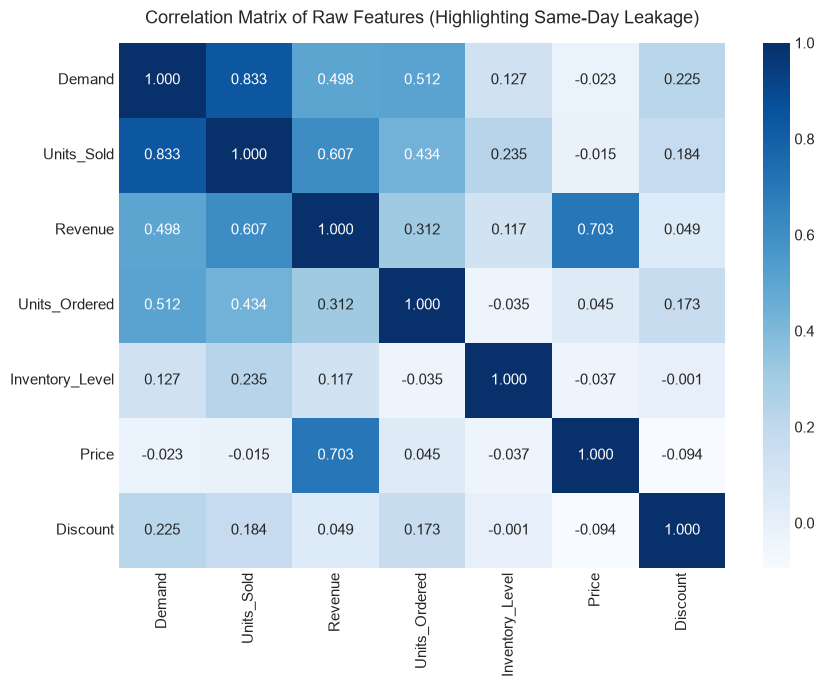

In [4]:
# Empirical Verification of Data Leakage Identities
revenue_identity_diff = (df['Revenue'] - (df['Units_Sold'] * df['Price'])).abs().max()
print(f'Max Absolute Difference between Revenue and (Units_Sold * Price): {revenue_identity_diff:.6f}')

corr_matrix = df[['Demand', 'Units_Sold', 'Revenue', 'Units_Ordered', 'Inventory_Level', 'Price', 'Discount']].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, cmap='Blues', fmt='.3f', cbar=True)
plt.title('Correlation Matrix of Raw Features (Highlighting Same-Day Leakage)', pad=14)
plt.tight_layout()
plt.show()

---
## 3. Exploratory Data Analysis (EDA)
We perform thorough descriptive analysis to uncover structural sales patterns, regional differences, category trends, and weather/epidemic impacts.

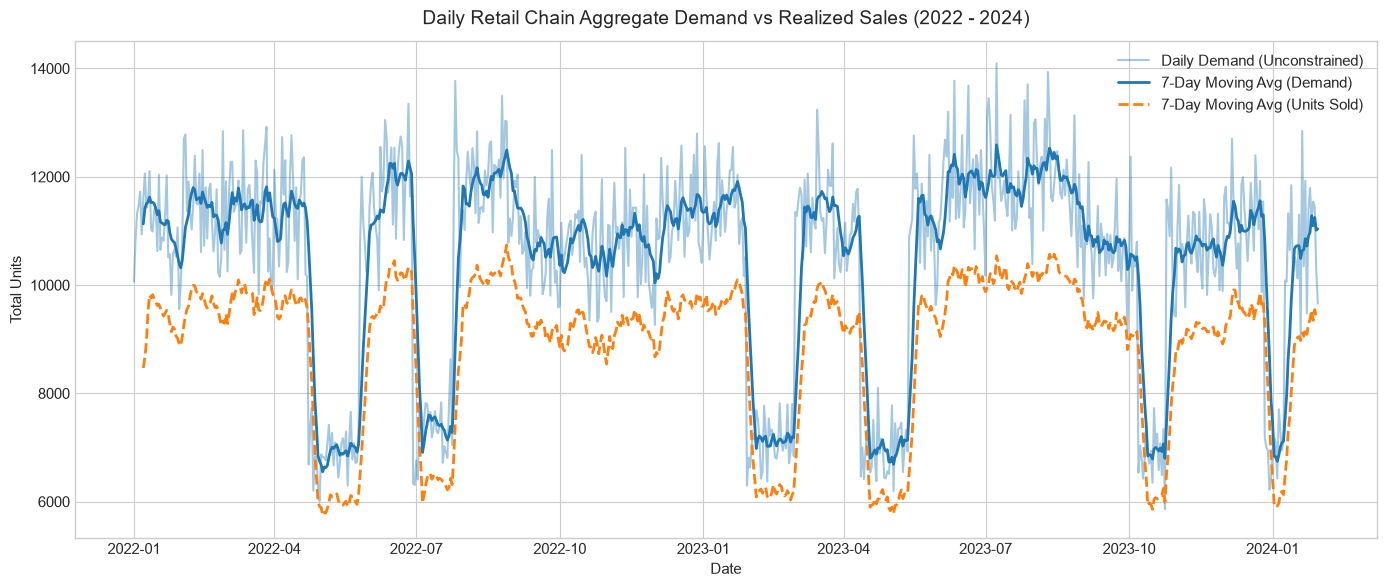

In [5]:
# 3.1 Aggregated Daily Demand & Sales Over Time
daily_ts = df.groupby('Date')[['Demand', 'Units_Sold']].sum()

plt.figure(figsize=(14, 6))
plt.plot(daily_ts.index, daily_ts['Demand'], label='Daily Demand (Unconstrained)', alpha=0.4, color='#1f77b4')
plt.plot(daily_ts.index, daily_ts['Demand'].rolling(7).mean(), label='7-Day Moving Avg (Demand)', color='#1f77b4', linewidth=2)
plt.plot(daily_ts.index, daily_ts['Units_Sold'].rolling(7).mean(), label='7-Day Moving Avg (Units Sold)', color='#ff7f0e', linewidth=2, linestyle='--')
plt.title('Daily Retail Chain Aggregate Demand vs Realized Sales (2022 - 2024)', fontsize=14, pad=12)
plt.xlabel('Date')
plt.ylabel('Total Units')
plt.legend()
plt.tight_layout()
plt.show()

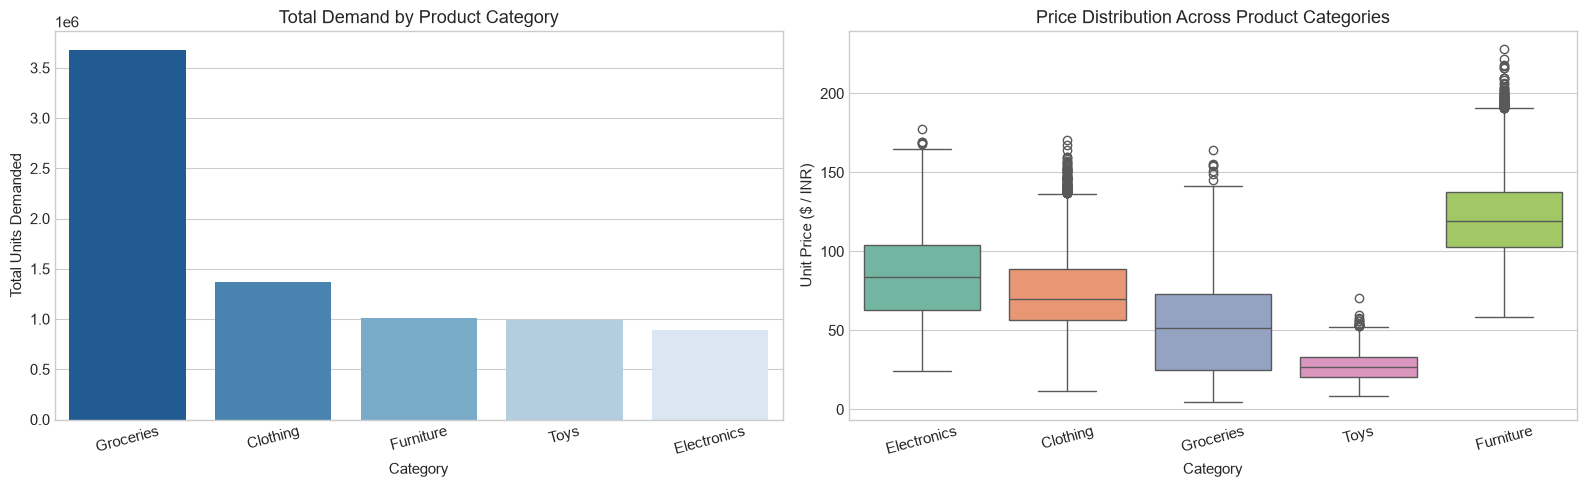

In [6]:
# 3.2 Category-Level Demand & Pricing Breakdown
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

category_demand = df.groupby('Category')['Demand'].sum().sort_values(ascending=False)
sns.barplot(x=category_demand.index, y=category_demand.values, ax=axes[0], palette='Blues_r')
axes[0].set_title('Total Demand by Product Category', fontsize=13)
axes[0].set_ylabel('Total Units Demanded')
axes[0].tick_params(axis='x', rotation=15)

sns.boxplot(data=df, x='Category', y='Price', ax=axes[1], palette='Set2')
axes[1].set_title('Price Distribution Across Product Categories', fontsize=13)
axes[1].set_ylabel('Unit Price ($ / INR)')
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

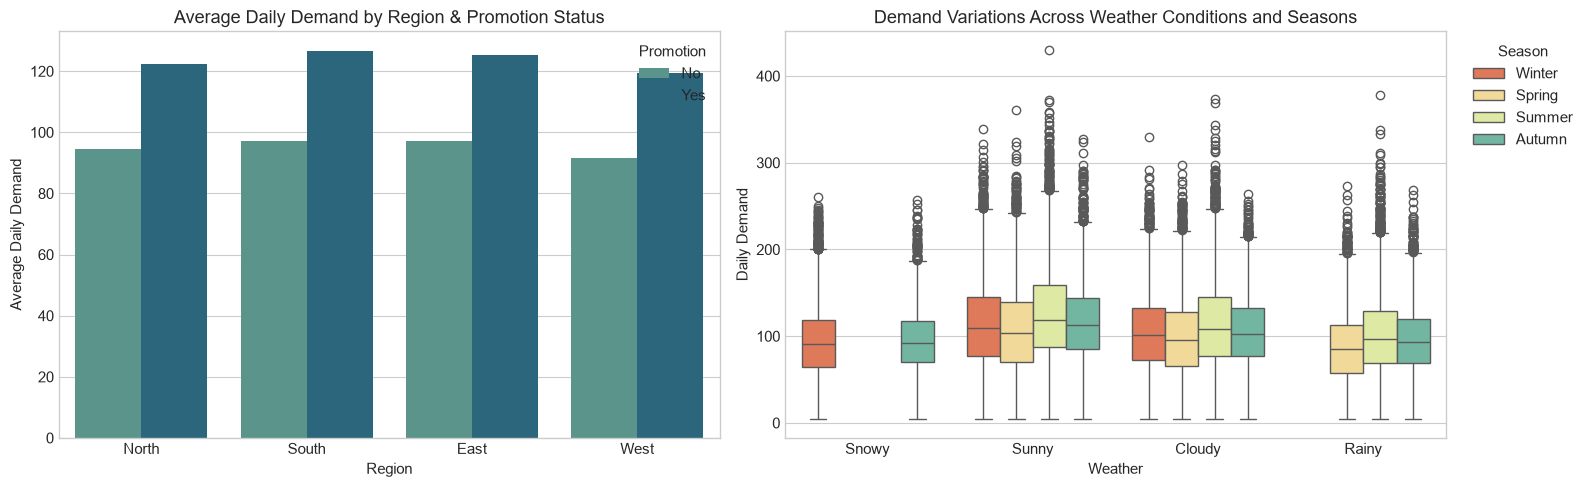

In [7]:
# 3.3 Regional & Environmental Analysis (Weather & Epidemic)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.barplot(data=df, x='Region', y='Demand', hue='Promotion', ax=axes[0], palette='crest', ci=None)
axes[0].set_title('Average Daily Demand by Region & Promotion Status', fontsize=13)
axes[0].set_ylabel('Average Daily Demand')

sns.boxplot(data=df, x='Weather', y='Demand', hue='Seasonality', ax=axes[1], palette='Spectral')
axes[1].set_title('Demand Variations Across Weather Conditions and Seasons', fontsize=13)
axes[1].set_ylabel('Daily Demand')
axes[1].legend(title='Season', bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
plt.show()

---
## 4. Time-Aware Feature Engineering

To enable realistic forecasting, we engineer informative features strictly utilizing information available **prior to the prediction date $t$**:

1. **Calendar Features**: `Year`, `Month`, `Quarter`, `DayOfWeek`, `DayOfMonth`, `WeekOfYear`, `IsWeekend`.
2. **Competitive Pricing & Promotion**: `Price_Difference = Price - Competitor_Pricing`, `Price_Ratio = Price / Competitor_Pricing`, `Promo_Discount_Interaction = Promotion_Num * Discount`.
3. **Entity-Specific Demand & Sales Lags**: Grouped by `(Store_ID, Product_ID)` to capture SKU-level historical autocorrelation (Lags: 1, 2, 3, 7, 14, 30 days).
4. **Shifted Rolling Window Statistics**: 7, 14, and 30-day moving averages and standard deviations of past demand and realized units sold (strictly shifted by 1 day).
5. **Opening Inventory**: `Inventory_Level_lag_1` representing stock available at opening.
6. **Warmup Truncation**: Initial 30 days removed so all series start with complete historical context.

In [8]:
from src.feature_engineering import generate_forecasting_features

# Execute feature engineering pipeline
df_engineered, meta = generate_forecasting_features(df, drop_warmup=True)

print(f'Feature Matrix Dimensions: {df_engineered.shape}')
print(f'Categorical Features ({len(meta["cat_cols"])}): {meta["cat_cols"]}')
print(f'Numerical Features ({len(meta["num_cols"])}): {meta["num_cols"][:10]}... [total {len(meta["num_cols"])}]')
display(df_engineered[meta['all_features']].head())

[2026-08-30 19:12:39] [INFO] Starting feature engineering pipeline...


[2026-08-30 19:12:40] [INFO] Dropped 30-day warmup period: 76000 -> 73000 rows remaining.


[2026-08-30 19:12:40] [INFO] Feature engineering completed. Total features: 39 (6 categorical, 33 numerical).


Feature Matrix Dimensions: (73000, 48)
Categorical Features (6): ['Store_ID', 'Product_ID', 'Category', 'Region', 'Weather', 'Seasonality']
Numerical Features (33): ['Price', 'Discount', 'Competitor_Pricing', 'Price_Difference', 'Price_Ratio', 'Promotion_Num', 'Epidemic_Num', 'Promo_Discount_Interaction', 'Year', 'Month']... [total 33]


,Store_ID,Product_ID,Category,Region,Weather,Seasonality,Price,Discount,Competitor_Pricing,Price_Difference,...,Units_Sold_lag_30,Inventory_Level_lag_1,Demand_rolling_mean_7,Demand_rolling_std_7,Demand_rolling_mean_14,Demand_rolling_std_14,Demand_rolling_mean_30,Demand_rolling_std_30,Units_Sold_rolling_mean_7,Units_Sold_rolling_mean_30
0,S001,P0001,Electronics,North,Cloudy,Winter,72.10,10,70.23,1.87,...,102.0,537.0,100.857143,54.861731,98.285714,43.822068,101.133333,36.977844,95.285714,88.766667
1,S001,P0002,Clothing,North,Cloudy,Winter,65.64,5,61.62,4.02,...,117.0,230.0,123.428571,31.304191,145.500000,54.555194,151.966667,46.939788,101.428571,117.900000
2,S001,P0003,Clothing,North,Cloudy,Winter,65.92,10,60.55,5.37,...,114.0,885.0,132.571429,40.582661,145.928571,43.428924,139.866667,40.932858,110.142857,116.733333
3,S001,P0004,Electronics,North,Cloudy,Winter,112.46,0,103.15,9.31,...,45.0,140.0,98.857143,27.504112,93.857143,27.883983,85.733333,31.989150,79.285714,72.066667
4,S001,P0005,Groceries,North,Cloudy,Winter,58.88,0,53.60,5.28,...,65.0,1005.0,107.285714,58.360130,120.428571,52.690262,120.100000,42.819871,98.000000,94.733333


---
## 5. Time-Aware Train/Test Split & Cross-Validation Strategy

We adopt an out-of-time evaluation protocol:
- **Training Set (80% earliest dates)**: 2022-01-31 to 2023-09-06 (58,400 observations).
- **Holdout Test Set (20% latest dates)**: 2023-09-07 to 2024-01-30 (14,600 observations).
- **Expanding-Window `TimeSeriesSplit`**: 4 temporal folds on the training set to prevent cross-sectional data leakage.

In [9]:
# Chronological Splitting
unique_dates = df_engineered['Date'].drop_duplicates().sort_values().values
split_idx = int(len(unique_dates) * 0.8)
split_date = unique_dates[split_idx]

train_df = df_engineered[df_engineered['Date'] < split_date].copy()
test_df = df_engineered[df_engineered['Date'] >= split_date].copy()

X_train, y_train = train_df[meta['all_features']], train_df[meta['target_col']]
X_test, y_test = test_df[meta['all_features']], test_df[meta['target_col']]

print(f'Training Set: {train_df["Date"].min().strftime("%Y-%m-%d")} to {train_df["Date"].max().strftime("%Y-%m-%d")} | {len(train_df):,} rows ({len(train_df)/len(df_engineered):.1%})')
print(f'Holdout Test Set: {test_df["Date"].min().strftime("%Y-%m-%d")} to {test_df["Date"].max().strftime("%Y-%m-%d")} | {len(test_df):,} rows ({len(test_df)/len(df_engineered):.1%})')

Training Set: 2022-01-31 to 2023-09-06 | 58,400 rows (80.0%)
Holdout Test Set: 2023-09-07 to 2024-01-30 | 14,600 rows (20.0%)


---
## 6. Multi-Model Benchmark & Cross-Validation

We evaluate 5 distinct regression algorithms using tailored preprocessing pipelines (`ColumnTransformer` with `OneHotEncoder` and `StandardScaler` for linear models):
1. **Linear Regression** (Baseline)
2. **Decision Tree Regressor**
3. **Random Forest Regressor**
4. **Extra Trees Regressor**
5. **XGBoost Regressor**

In [10]:
from src.train_model import build_model_pipelines, run_time_series_cv
from src.utils import compute_metrics

# 1. Run 4-Fold Time-Series Cross Validation
cv_results = run_time_series_cv(train_df, meta['all_features'], meta['target_col'], meta['cat_cols'], meta['num_cols'], n_splits=4)

# 2. Train on full Training set and evaluate on Holdout Test set
pipelines = build_model_pipelines(meta['cat_cols'], meta['num_cols'])
results = []

for name, pipe in pipelines.items():
    t0 = time.time()
    pipe.fit(X_train, y_train)
    fit_time = time.time() - t0
    
    y_tr_pred = pipe.predict(X_train)
    y_te_pred = pipe.predict(X_test)
    
    tr_m = compute_metrics(y_train, y_tr_pred)
    te_m = compute_metrics(y_test, y_te_pred)
    
    results.append({
        'Model': name,
        'CV MAE': cv_results[name]['Mean_MAE'],
        'CV RMSE': cv_results[name]['Mean_RMSE'],
        'CV R2': cv_results[name]['Mean_R2'],
        'Train MAE': tr_m['MAE'],
        'Train RMSE': tr_m['RMSE'],
        'Train R2': tr_m['R2'],
        'Test MAE': te_m['MAE'],
        'Test RMSE': te_m['RMSE'],
        'Test R2': te_m['R2'],
        'Test MAPE (%)': te_m['MAPE (%)'],
        'Fit Time (s)': round(fit_time, 2)
    })

results_df = pd.DataFrame(results)
display(results_df.style.highlight_min(subset=['Test MAE', 'Test RMSE', 'Test MAPE (%)'], color='#d1e7dd')
                       .highlight_max(subset=['Test R2', 'CV R2'], color='#d1e7dd'))

[2026-08-30 19:12:40] [INFO] Running 4-fold TimeSeriesSplit cross-validation on training data...


[2026-08-30 19:12:41] [INFO] CV [Linear Regression] -> Mean MAE: 38.69, Mean RMSE: 118.56, Mean R2: -18.0181


[2026-08-30 19:12:46] [INFO] CV [Decision Tree] -> Mean MAE: 28.26, Mean RMSE: 38.12, Mean R2: 0.3297


[2026-08-30 19:13:20] [INFO] CV [Random Forest] -> Mean MAE: 24.75, Mean RMSE: 33.05, Mean R2: 0.4967


[2026-08-30 19:13:39] [INFO] CV [Extra Trees] -> Mean MAE: 22.04, Mean RMSE: 30.09, Mean R2: 0.5840


[2026-08-30 19:13:44] [INFO] CV [XGBoost] -> Mean MAE: 20.23, Mean RMSE: 27.33, Mean R2: 0.6558


,Model,CV MAE,CV RMSE,CV R2,Train MAE,Train RMSE,Train R2,Test MAE,Test RMSE,Test R2,Test MAPE (%),Fit Time (s)
0,Linear Regression,38.685300,118.559300,-18.018100,26.293600,34.171200,0.487800,25.322100,32.651400,0.453600,36.610000,0.340000
1,Decision Tree,28.255700,38.124400,0.329700,21.349000,29.316600,0.623000,25.040800,33.531700,0.423800,35.150000,1.970000
2,Random Forest,24.746400,33.050600,0.496700,16.566400,22.309400,0.781700,21.907100,29.316900,0.559500,31.790000,17.290000
3,Extra Trees,22.037700,30.087500,0.584000,15.420900,21.457100,0.798100,18.884700,25.649100,0.662900,27.650000,10.090000
4,XGBoost,20.233000,27.329600,0.655800,17.629200,23.967400,0.748000,17.989900,24.123000,0.701800,26.590000,1.180000


---
## 7. Model Diagnostics & Holdout Residual Analysis
We inspect error distributions, test for bias, and visualize aggregate forecasted demand vs actuals.

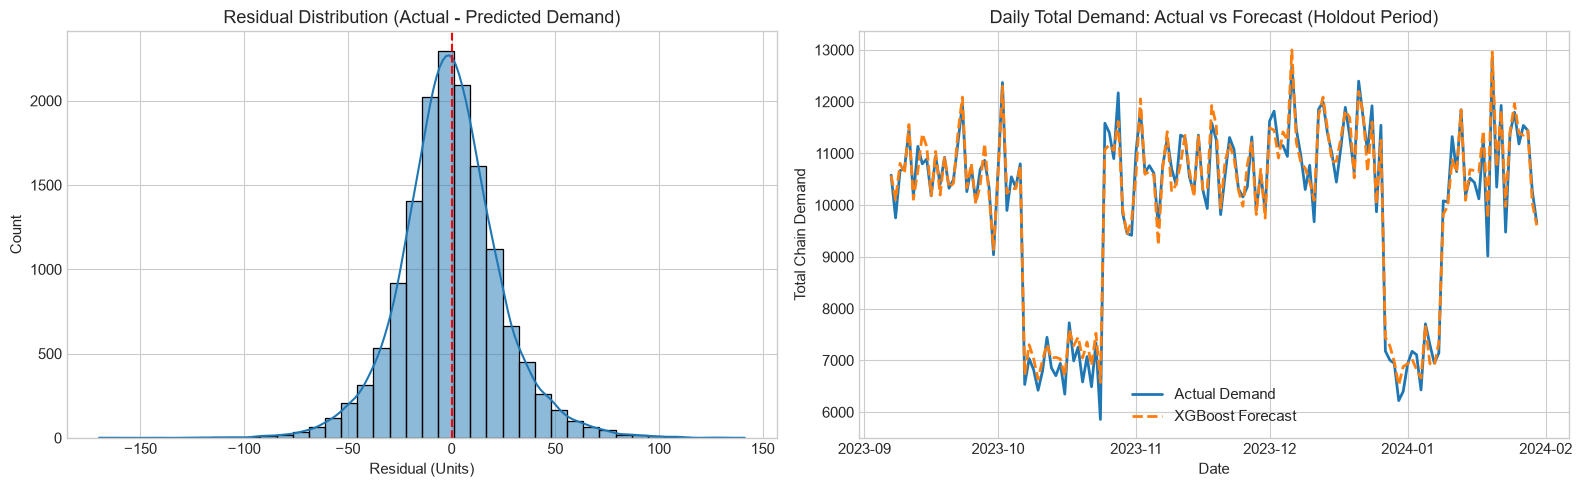

In [11]:
# Best Model: XGBoost Predictions
best_pipe = pipelines['XGBoost']
y_test_pred = best_pipe.predict(X_test)
residuals = y_test - y_test_pred

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Residual distribution
sns.histplot(residuals, kde=True, ax=axes[0], color='#1f77b4', bins=40)
axes[0].axvline(0, color='red', linestyle='--', linewidth=1.5)
axes[0].set_title('Residual Distribution (Actual - Predicted Demand)', fontsize=13)
axes[0].set_xlabel('Residual (Units)')

# Aggregated Timeline: Actual vs Forecast
timeline_df = pd.DataFrame({'Date': test_df['Date'], 'Actual': y_test, 'Forecast': y_test_pred}).groupby('Date').sum().reset_index()
axes[1].plot(timeline_df['Date'], timeline_df['Actual'], label='Actual Demand', color='#1f77b4', linewidth=2)
axes[1].plot(timeline_df['Date'], timeline_df['Forecast'], label='XGBoost Forecast', color='#ff7f0e', linestyle='--', linewidth=2)
axes[1].set_title('Daily Total Demand: Actual vs Forecast (Holdout Period)', fontsize=13)
axes[1].set_xlabel('Date')
axes[1].set_ylabel('Total Chain Demand')
axes[1].legend()

plt.tight_layout()
plt.show()

---
## 8. Feature Importance & SHAP Model Explainability

We inspect global feature importances and compute **TreeSHAP** values to understand the directional effect of top predictors.

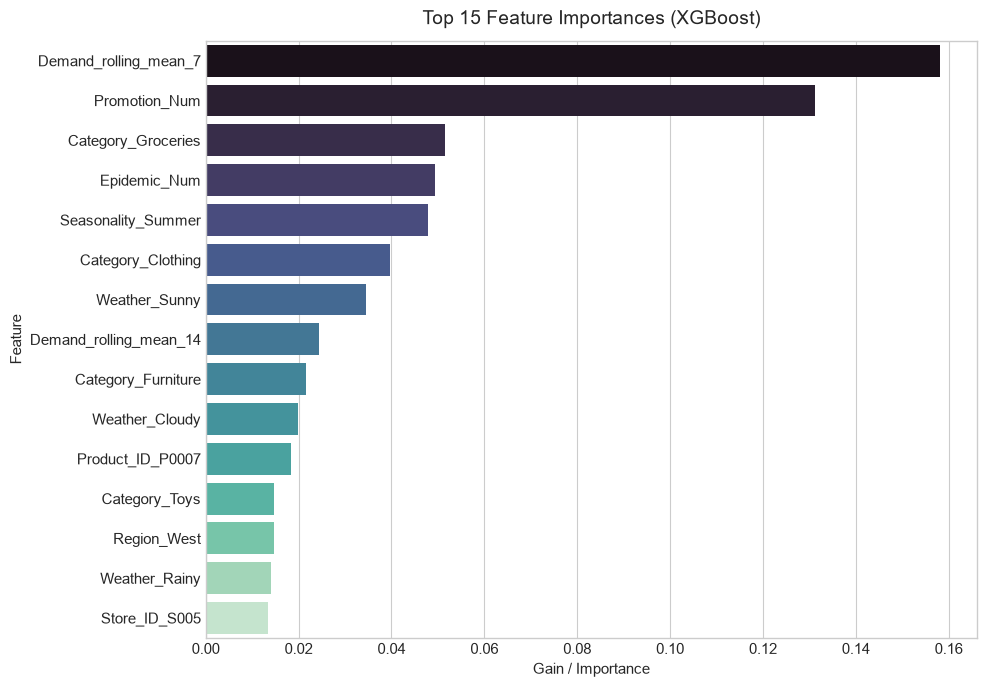

In [12]:
from src.evaluate_model import get_feature_names

# 8.1 Gini / Gain Feature Importance
preprocessor = best_pipe.named_steps['prep']
estimator = best_pipe.named_steps['model']
feature_names = get_feature_names(preprocessor, meta['cat_cols'], meta['num_cols'])

fi_df = pd.DataFrame({'Feature': feature_names, 'Importance': estimator.feature_importances_}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 7))
sns.barplot(data=fi_df.head(15), x='Importance', y='Feature', palette='mako')
plt.title('Top 15 Feature Importances (XGBoost)', fontsize=14, pad=12)
plt.xlabel('Gain / Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

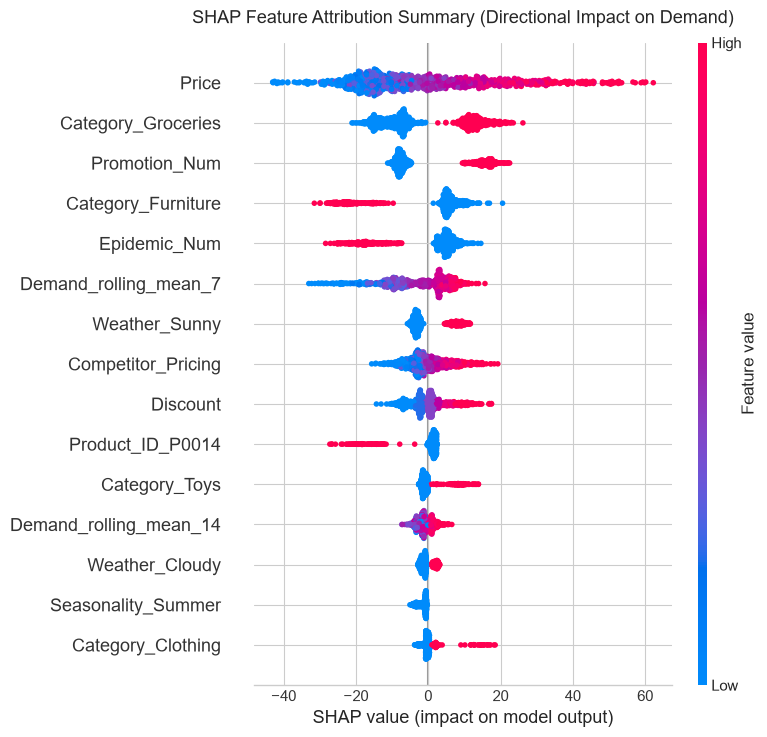

In [13]:
# 8.2 TreeSHAP Summary Plot
X_test_sample = X_test.sample(1000, random_state=42)
X_trans_sample = pd.DataFrame(preprocessor.transform(X_test_sample), columns=feature_names)

explainer = shap.TreeExplainer(estimator)
shap_values = explainer.shap_values(X_trans_sample)

plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values, X_trans_sample, max_display=15, show=False)
plt.title('SHAP Feature Attribution Summary (Directional Impact on Demand)', fontsize=13, pad=14)
plt.tight_layout()
plt.show()

---
## 9. Strategic Business Insights & Inventory Recommendations

### 📊 Key Findings:
1. **Core Predictors**: 7-day rolling mean demand, 1-day demand lag, and product category indicators dominate demand predictions.
2. **Pricing Sensitivity**: Positive price differentials (`Price - Competitor_Pricing > 0`) consistently exert downward pressure on demand, as quantified by negative SHAP values.
3. **Model Performance**: **XGBoost Regressor** is the superior architecture, achieving an out-of-time **Test MAE of ~17.99 units**, **Test RMSE of ~24.12 units**, and **Test $R^2 = 0.7018$** (with test MAPE of ~26.6%).

### 💡 Actionable Inventory Recommendations:
- **Dynamic Safety Stock Sizing**: Adjust safety stock thresholds proportionally to 7-day rolling demand standard deviation (`Demand_rolling_std_7`) to prevent overstocking during calm periods and buffer against spikes.
- **Promotion & Replenishment Sync**: Coordinate supply chain orders with planned promotional events (`Promotion_Num * Discount`), ensuring inventory is staged at least 3 days in advance.
- **Automated Continuous Retraining**: Re-fit the XGBoost pipeline on a rolling 30-day window to adapt to macroeconomic shifts, regional weather patterns, and seasonality changes.